In [1]:
from knot_repo import available_unknots as unknots #This file holds many examples used in our paper
from drawing_rectangular_diagrams_src import draw_rectangular_diagram as draw
from unknotting_algorithm import *
import random 
import csv
import ast
import concurrent.futures
import time

In [2]:
#unknots = []

# Open the CSV file
#with open('very_hard_unknots_vertex_sets.csv', mode='r') as file:
#    csv_reader = csv.reader(file)
#    
#    # Process each row in the CSV
#    for row in csv_reader:
#        # Convert each string '[x, y]' into a real list [x, y]
#        clean_row = [ast.literal_eval(vertex) for vertex in row]
#        unknots.append(clean_row)


unknots = []

with open('Dowker.17.10_vertex_sets.csv', mode='r') as file:
    for line in file:
        line = line.strip()
        if line:
            unknots.append(ast.literal_eval(line))

In [3]:
""""v_1b_simple=[]
not_v_1b_simple=[]
for i,unknot in enumerate(unknots):
    print('testing unknot',i)
    print('current number of v_1b_simple',len(v_1b_simple))
    print('Percentage of v_1b_simple so far:',len(v_1b_simple)/(i+1),'%')
    VS=All_Virtual_Boxes_Simplification_Updated_Not_Verbose(unknot)
    if(len(VS[-1])//2)>2:
        not_v_1b_simple.append(i)
    else:
        v_1b_simple.append(i)"""

'"v_1b_simple=[]\nnot_v_1b_simple=[]\nfor i,unknot in enumerate(unknots):\n    print(\'testing unknot\',i)\n    print(\'current number of v_1b_simple\',len(v_1b_simple))\n    print(\'Percentage of v_1b_simple so far:\',len(v_1b_simple)/(i+1),\'%\')\n    VS=All_Virtual_Boxes_Simplification_Updated_Not_Verbose(unknot)\n    if(len(VS[-1])//2)>2:\n        not_v_1b_simple.append(i)\n    else:\n        v_1b_simple.append(i)'

Starting parallel processing on 1 cores for 1004 unknots...
The box below has a generalized v1b simplification


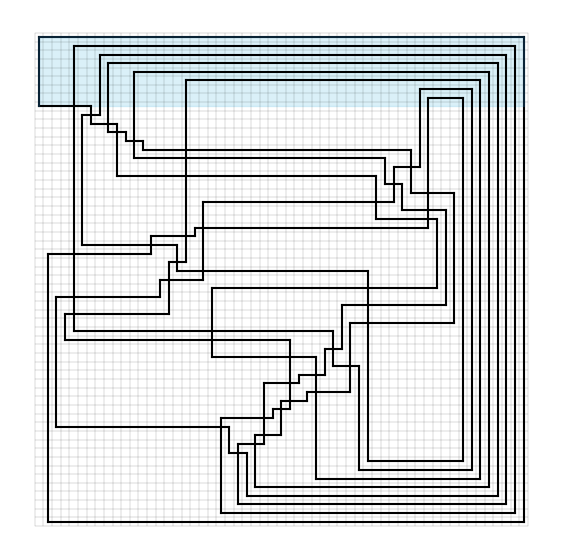

The box below has a generalized v1b simplification


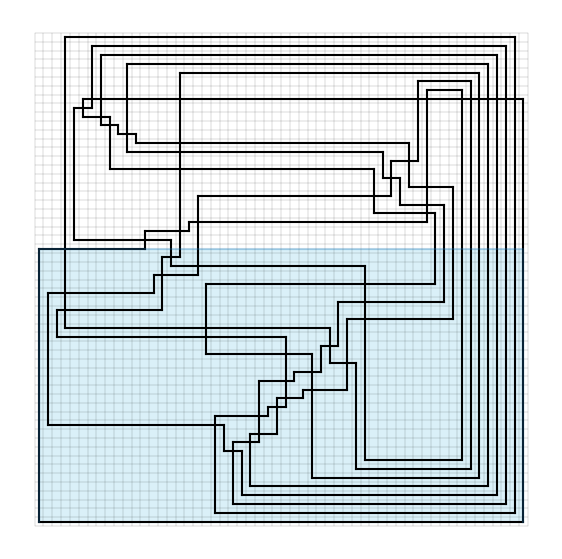

The box below has a generalized v1b simplification


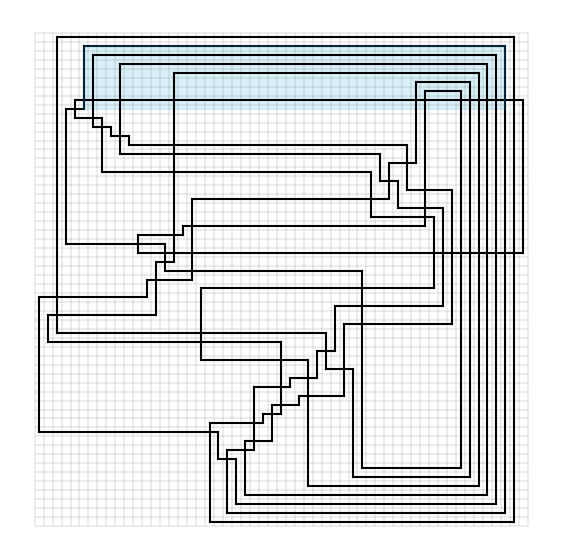

The box below has a generalized v1b simplification


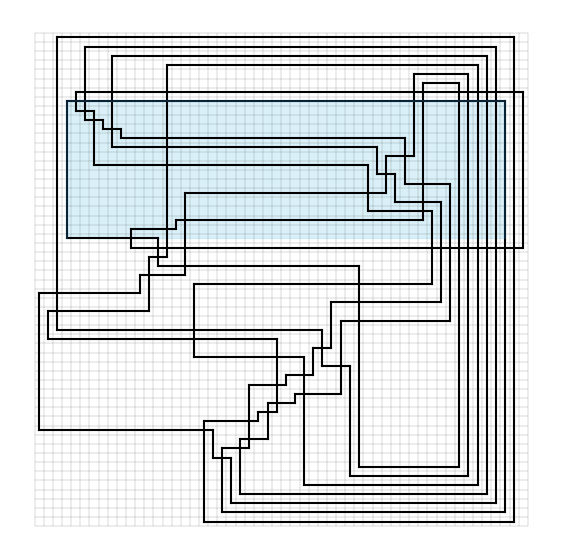

The box below has a generalized v1b simplification


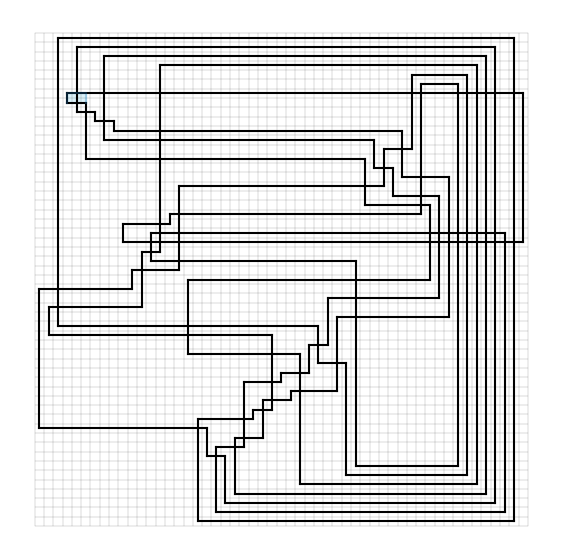

The box below has a generalized v1b simplification


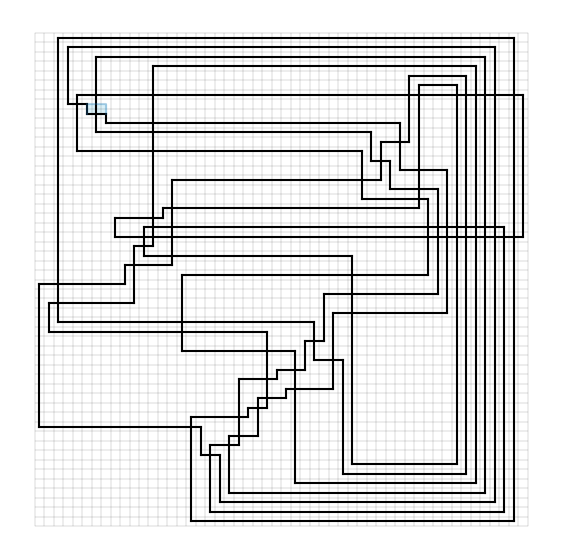

The box below has a generalized v1b simplification


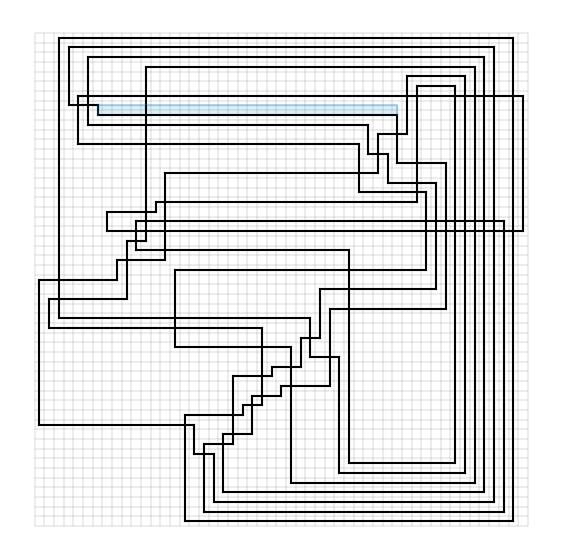

The box below has a generalized v1b simplification


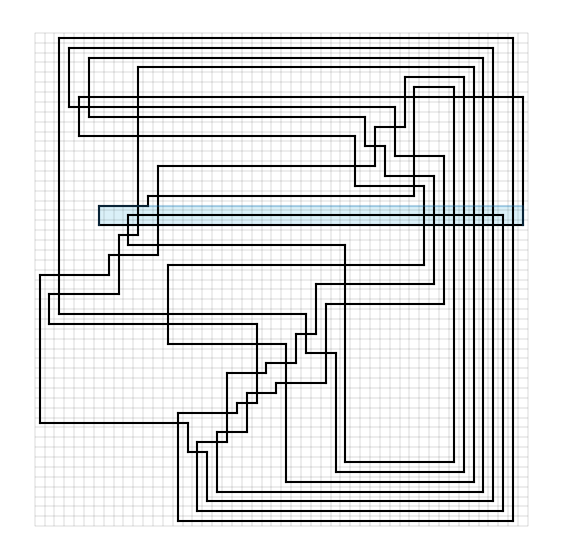

The box below has a generalized v1b simplification


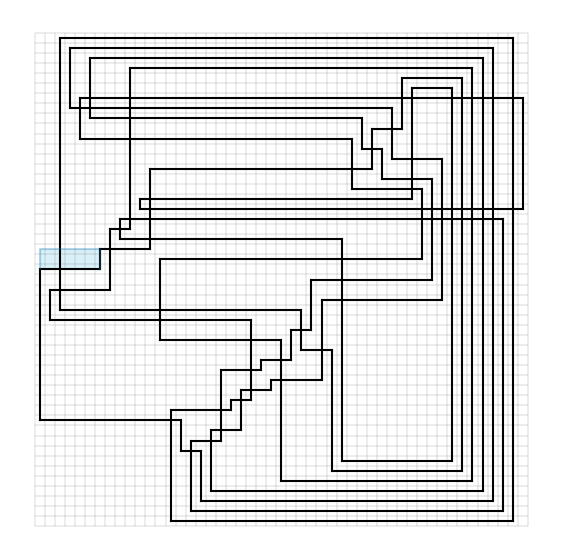

The box below has a generalized v1b simplification


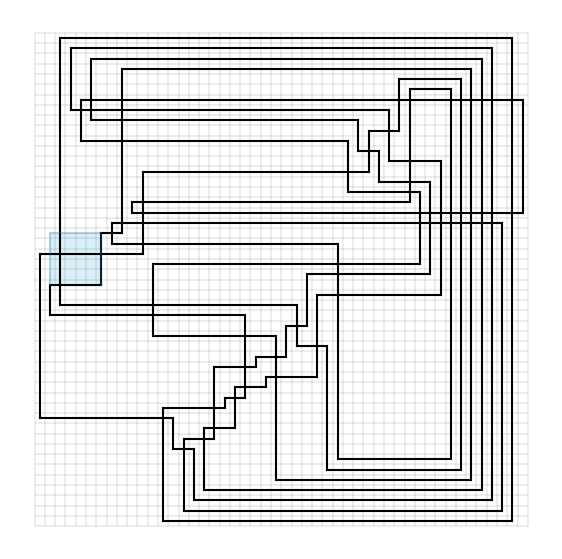

The box below has a generalized v1b simplification


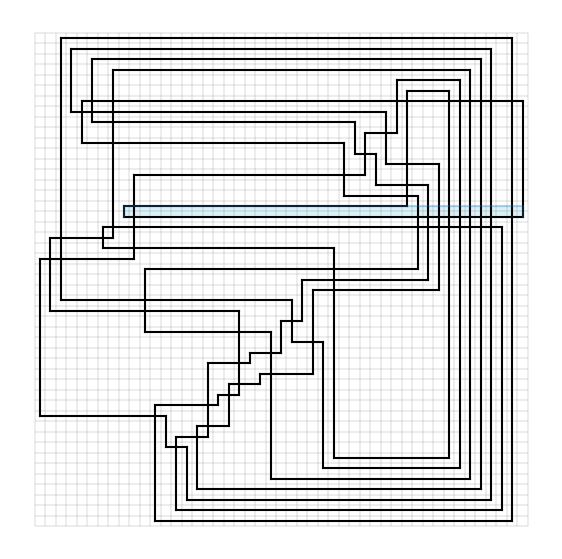

The box below has a generalized v1b simplification


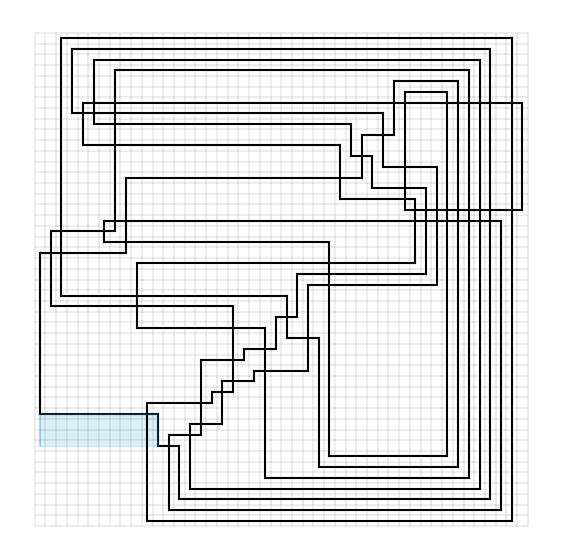

The box below has a generalized v1b simplification


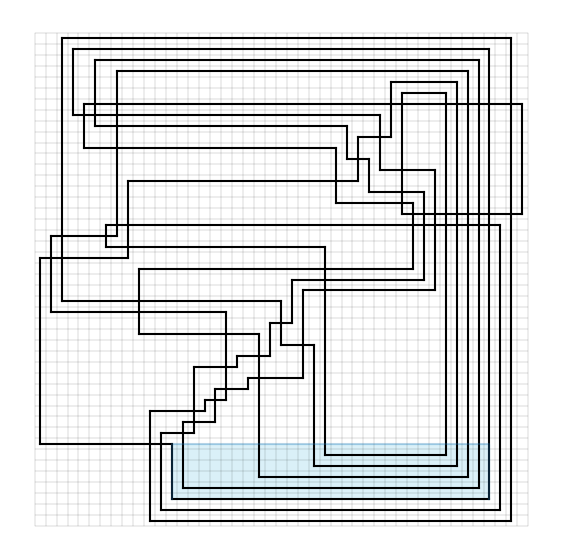

The box below has a generalized v1b simplification


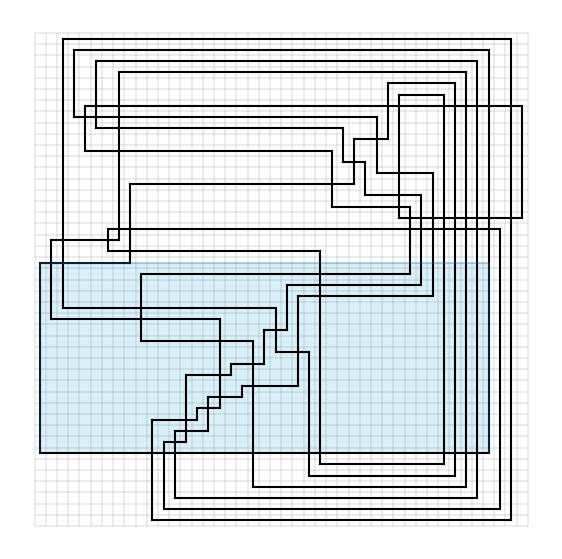

The box below has a generalized v1b simplification


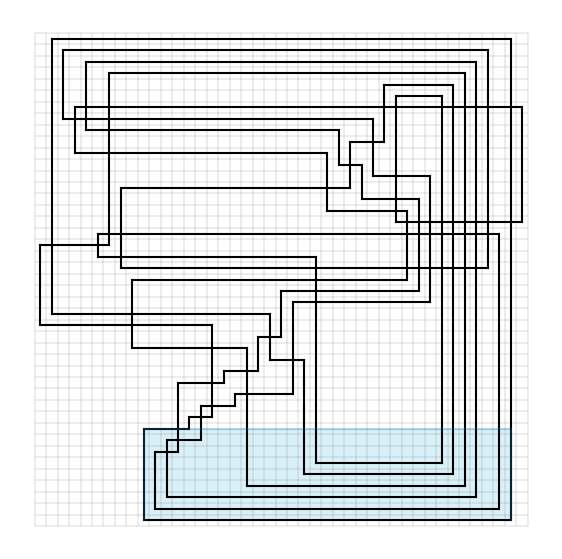

The box below has a generalized v1b simplification


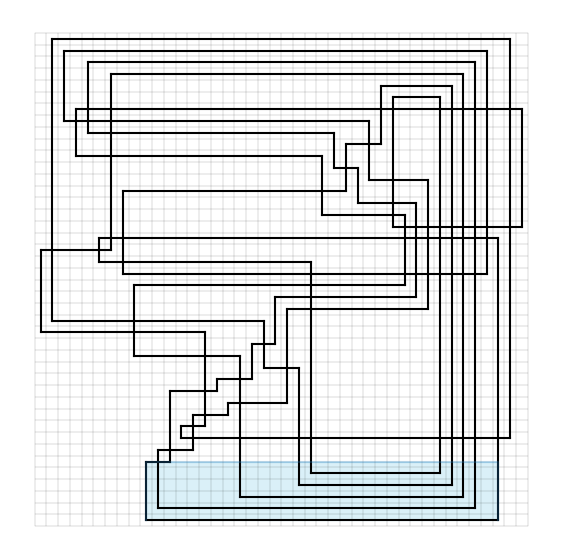

The box below has a generalized v1b simplification


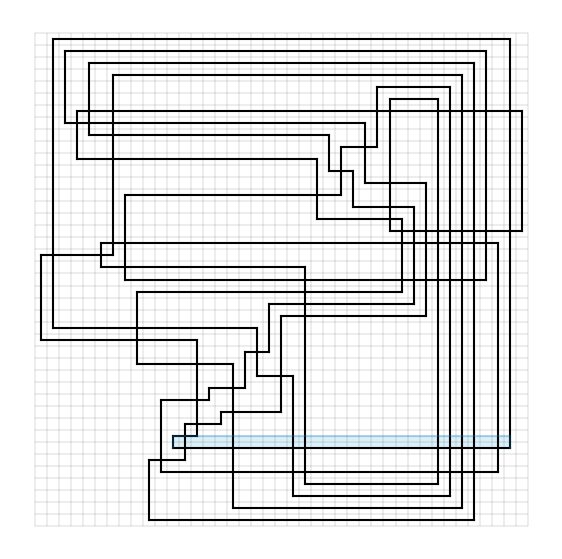

The box below has a generalized v1b simplification


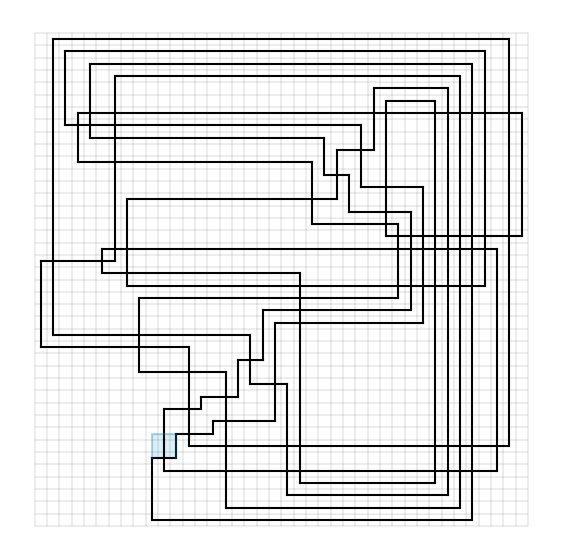

The box below has a generalized v1b simplification


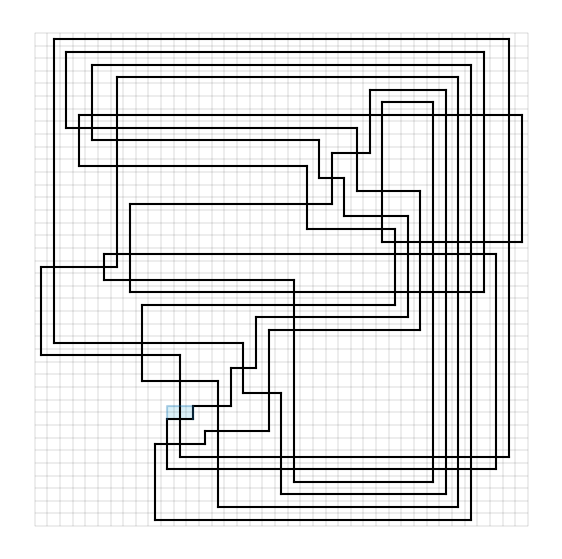

The box below has a generalized v1b simplification


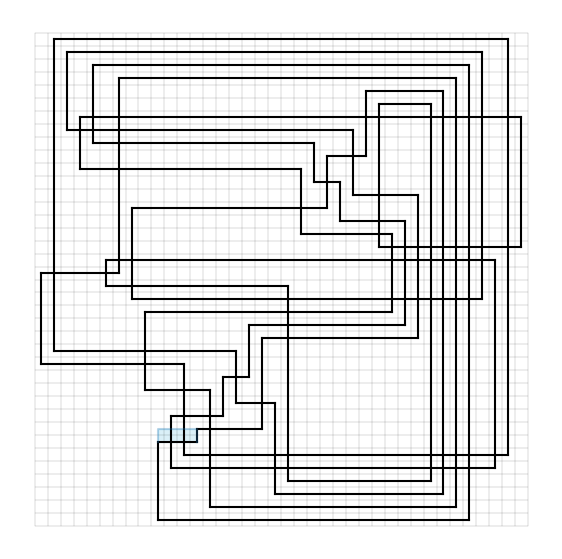

The box below has a generalized v1b simplification


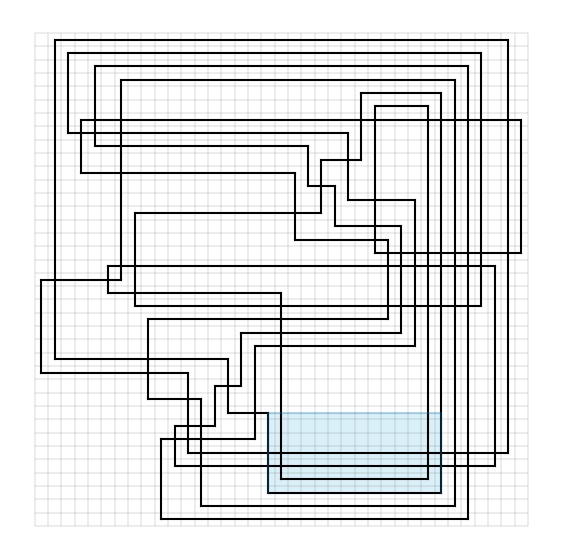

The box below has a generalized v1b simplification


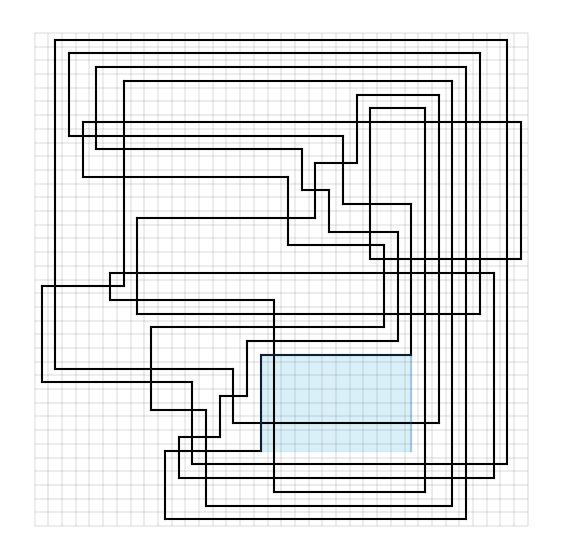

The box below has a generalized v1b simplification


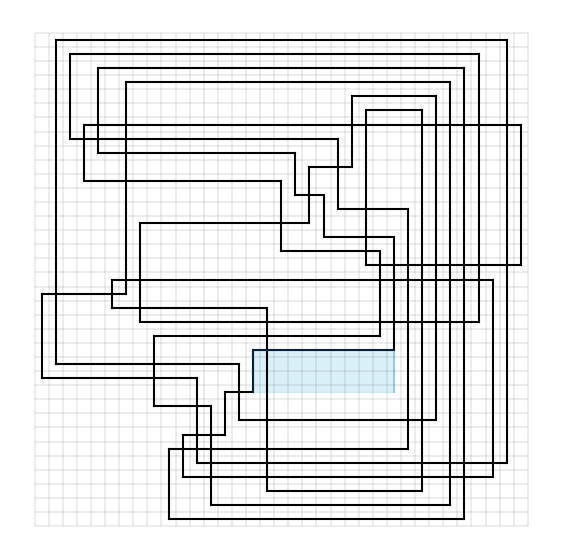

The box below has a generalized v1b simplification


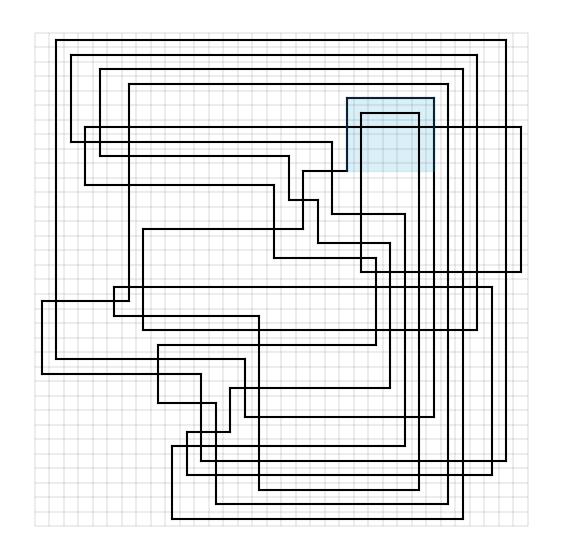

The box below has a generalized v1b simplification


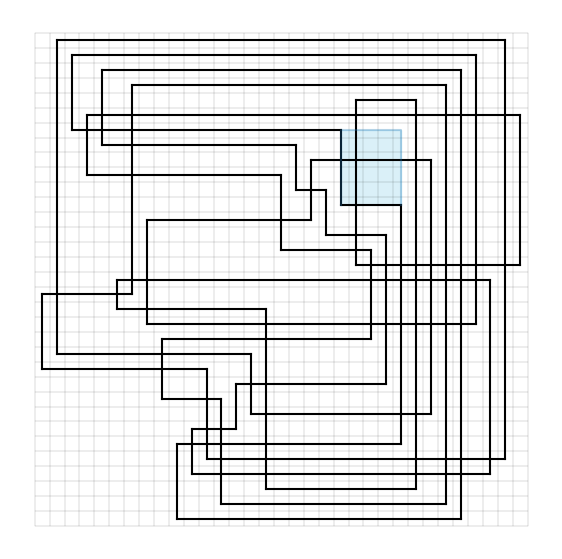

The box below has a generalized v1b simplification


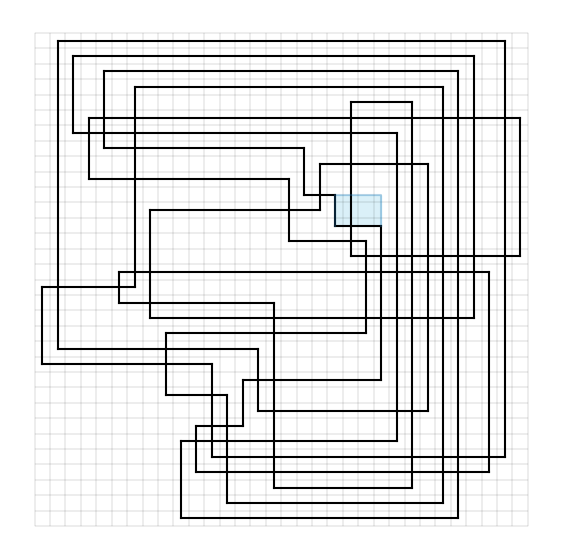

The box below has a generalized v1b simplification


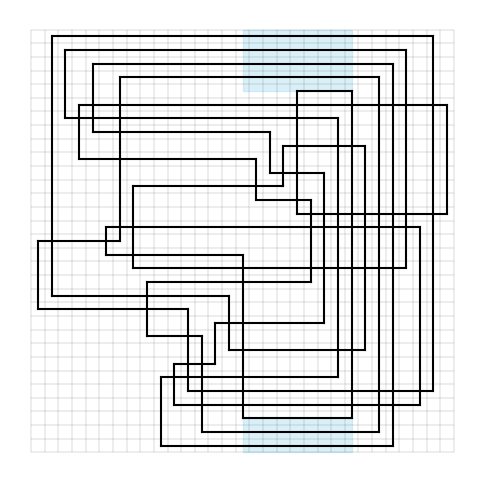

The box below has a generalized v1b simplification


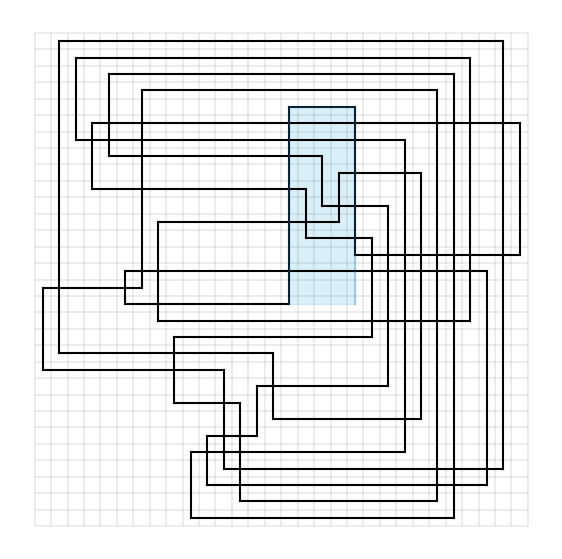

The box below has a generalized v1b simplification


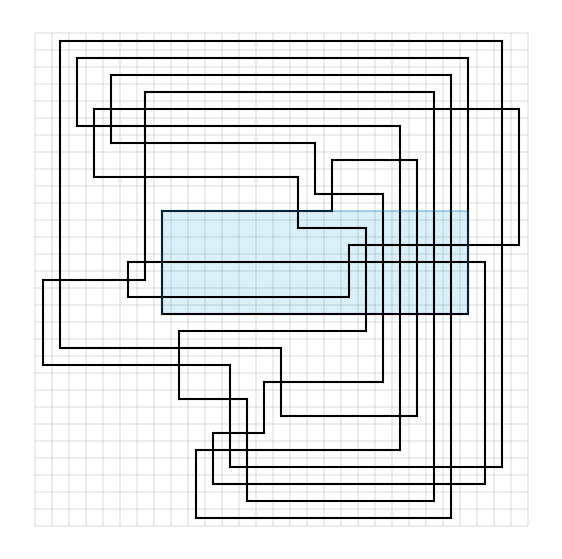

The box below has a generalized v1b simplification


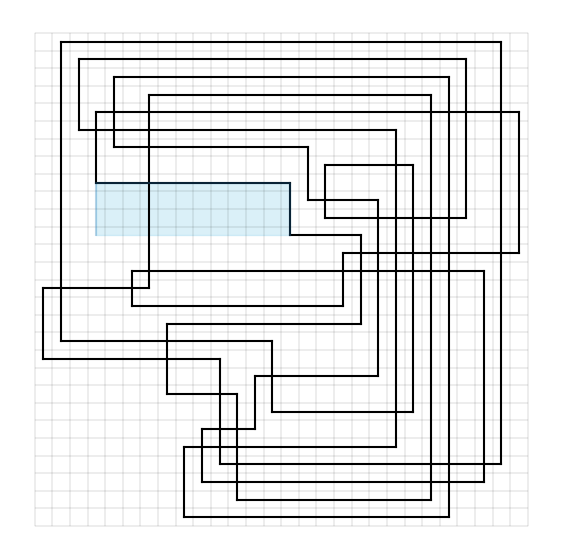

The box below has a generalized v1b simplification


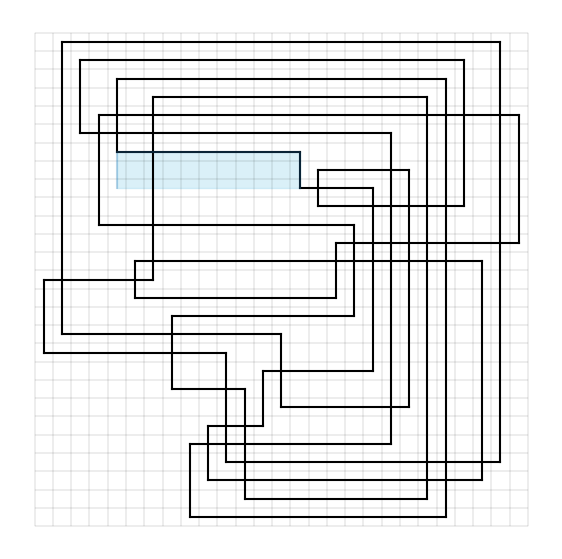

The box below has a generalized v1b simplification


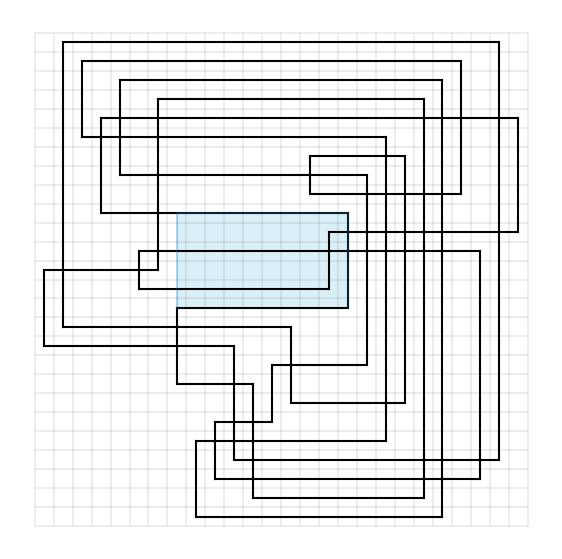

The box below has a generalized v1b simplification


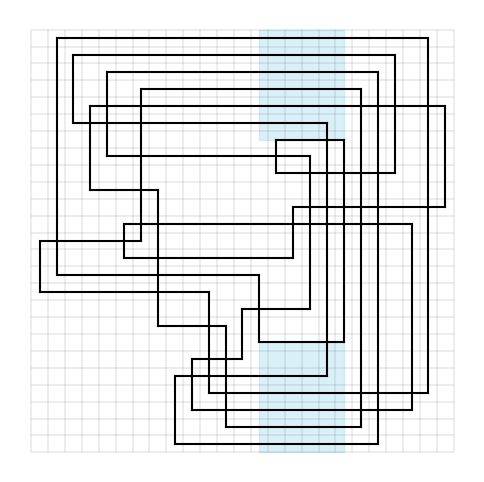

The box below has a generalized v1b simplification


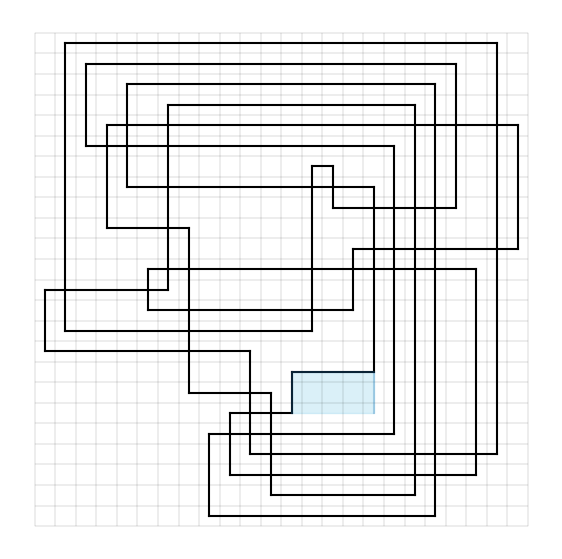

The box below has a generalized v1b simplification


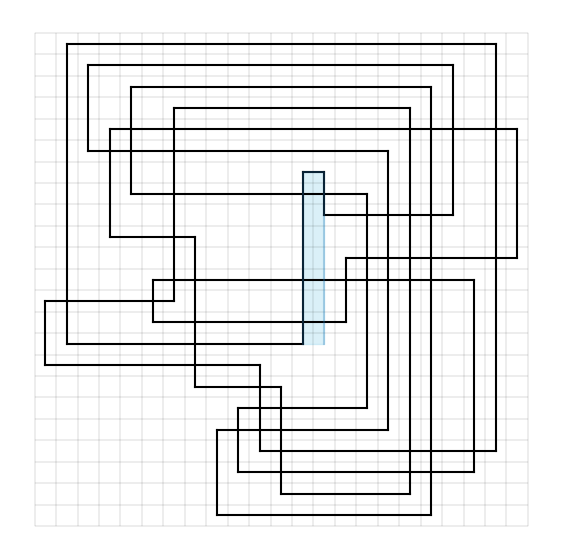

The box below has a generalized v1b simplification


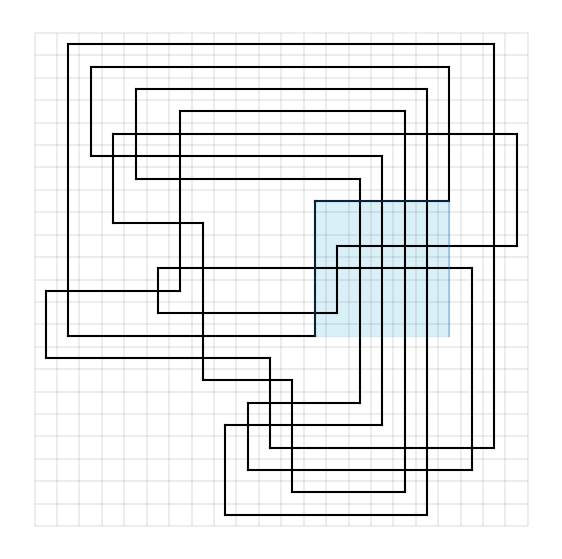

The box below has a generalized v1b simplification


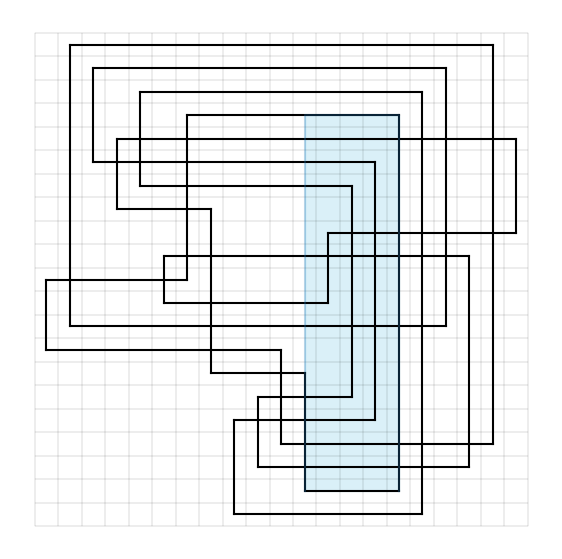

The box below has a generalized v1b simplification


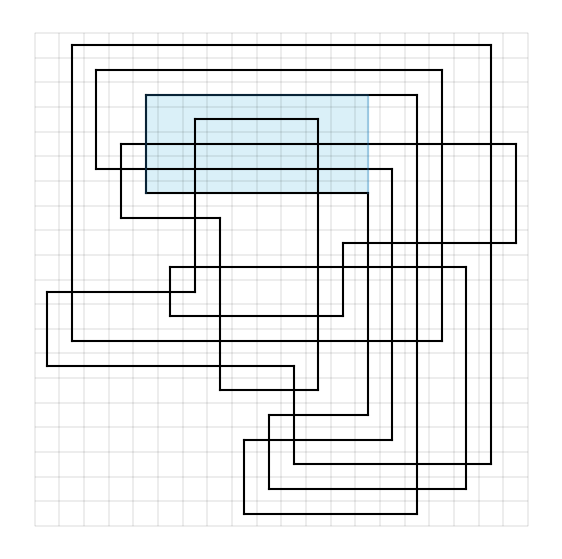

The box below has a generalized v1b simplification


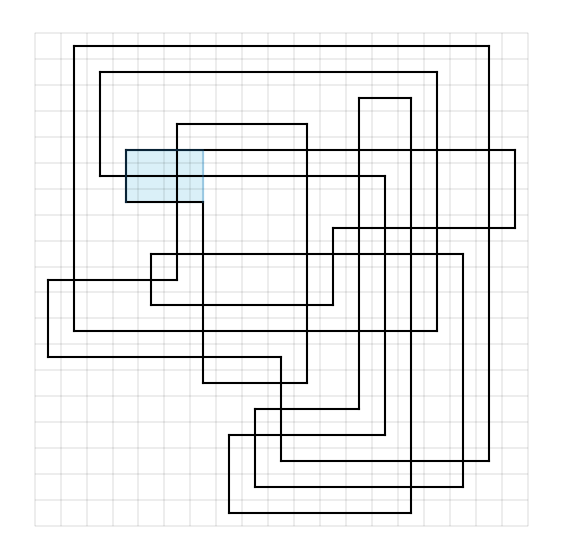

The box below has a generalized v1b simplification


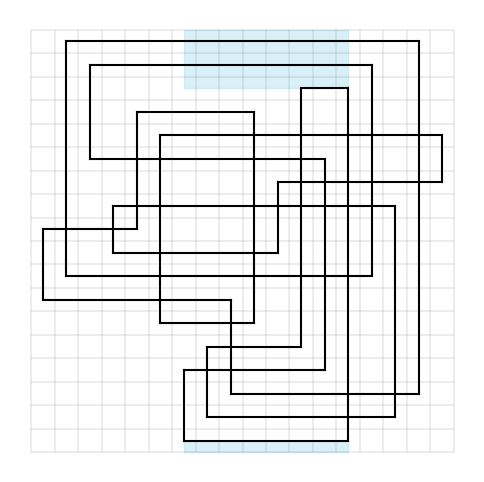

The box below has a generalized v1b simplification


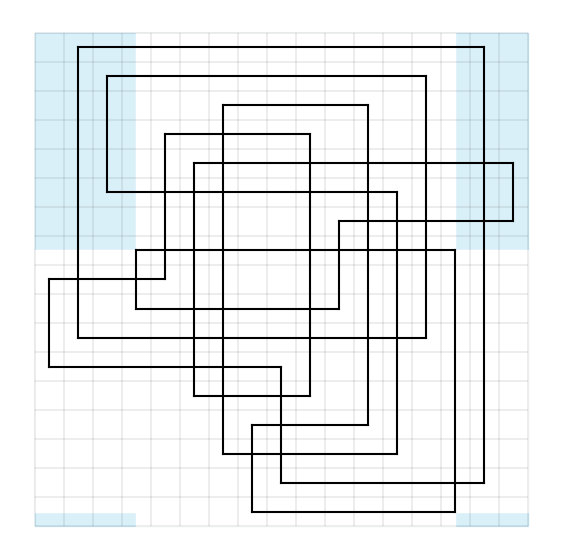

The box below has a generalized v1b simplification


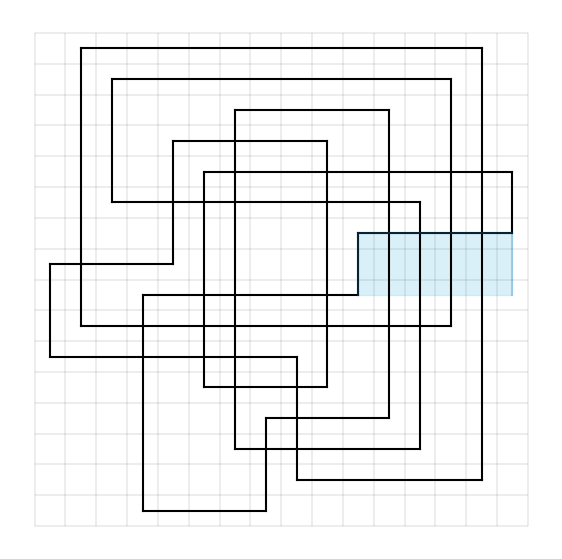

The box below has a generalized v1b simplification


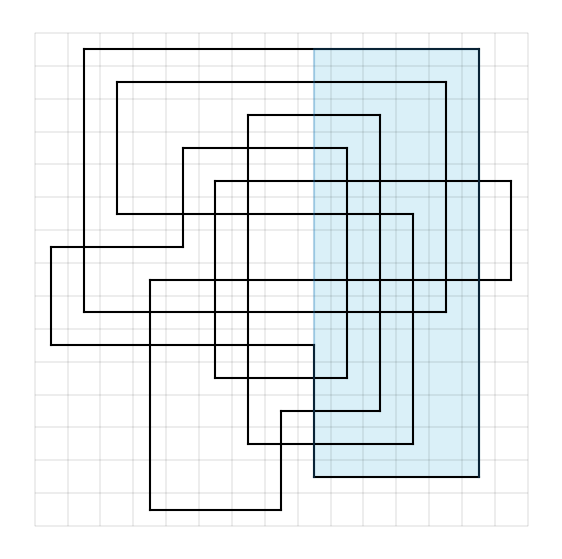

The box below has a generalized v1b simplification


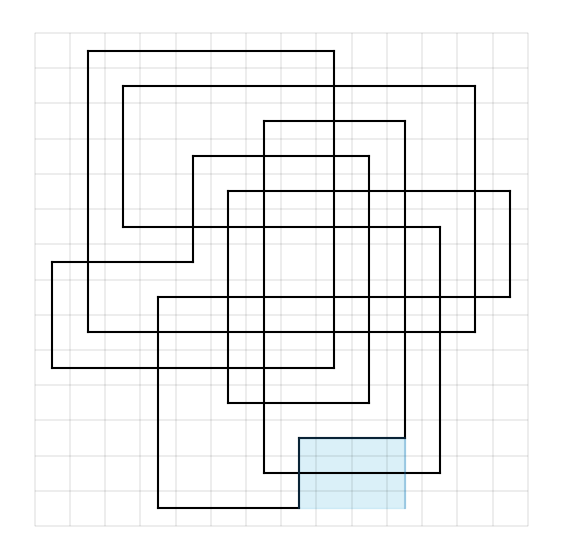

The box below has a generalized v1b simplification


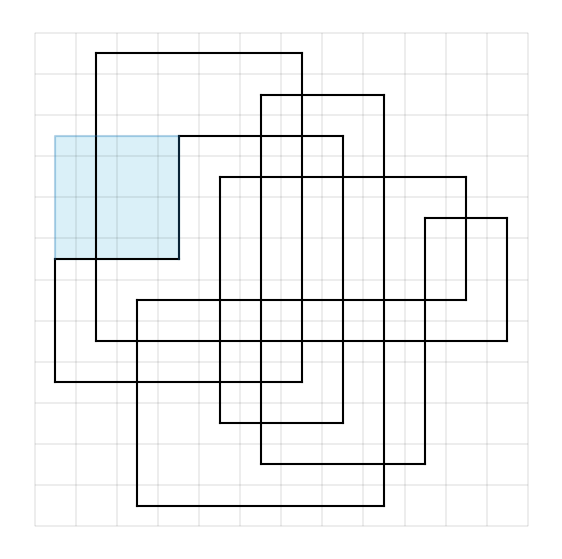

The box below has a generalized v1b simplification


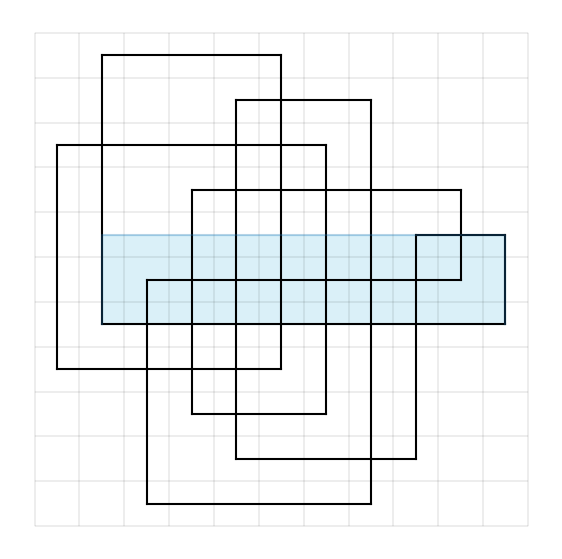

The box below has a generalized v1b simplification


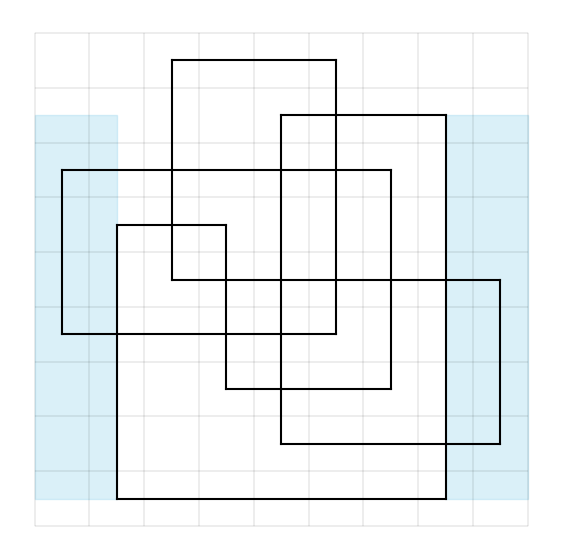

The box below has a generalized v1b simplification


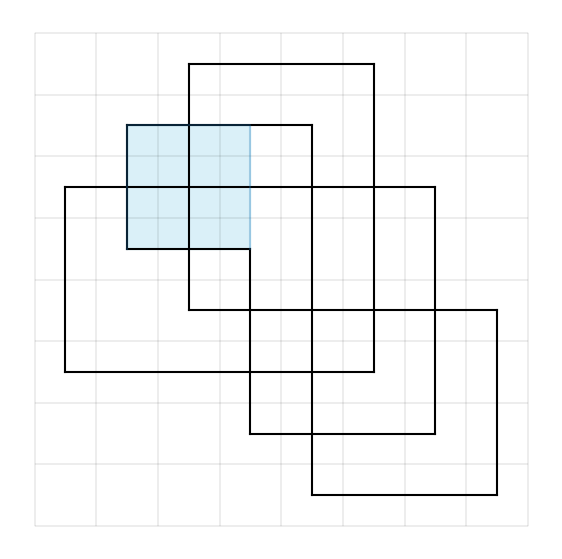

The box below has a generalized v1b simplification


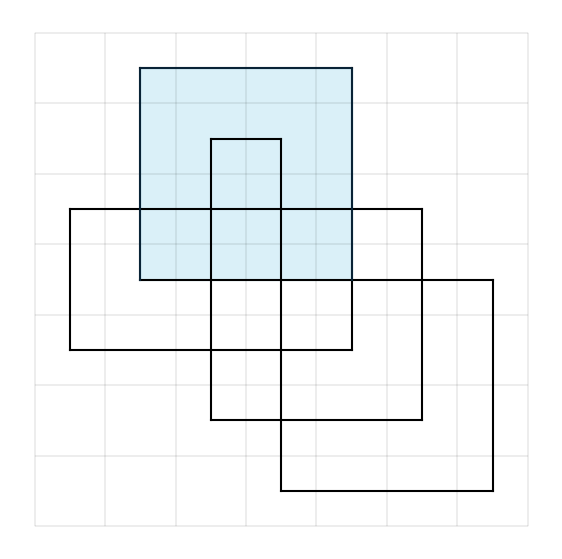

The box below has a generalized v1b simplification


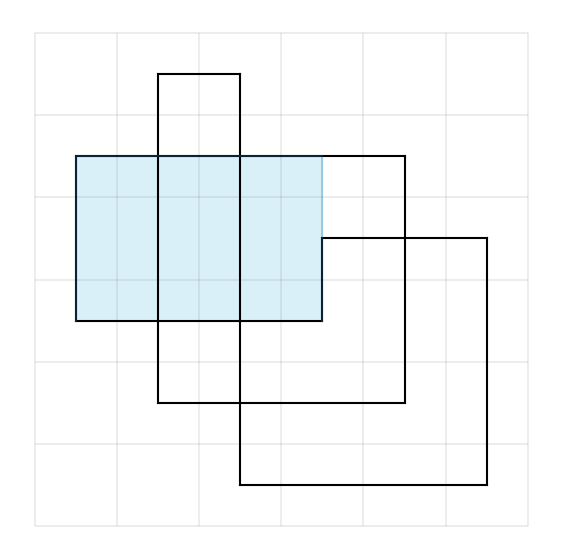

The box below has a generalized v1b simplification


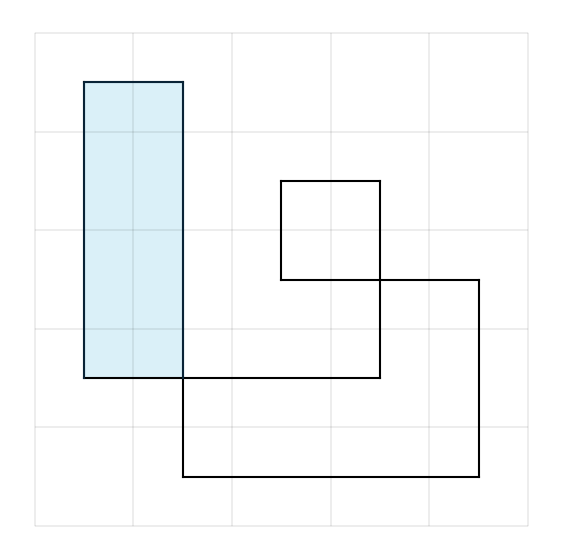

The box below has a generalized v1b simplification


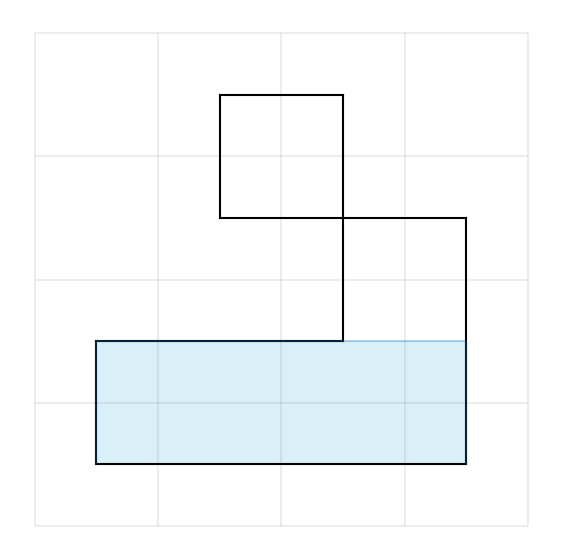

The box below has a generalized v1b simplification


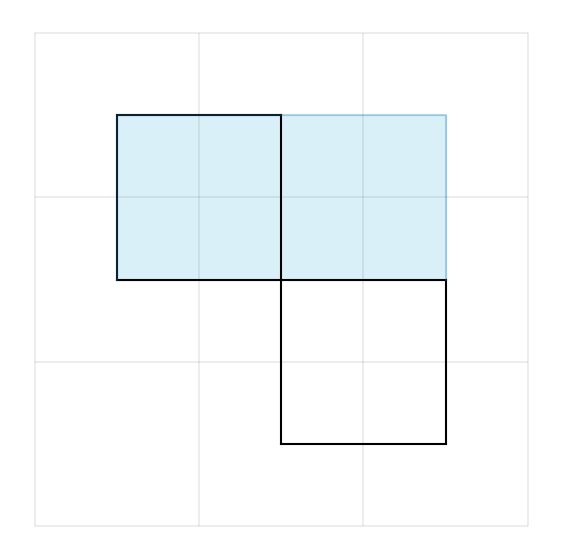

The box below has a generalized v1b simplification


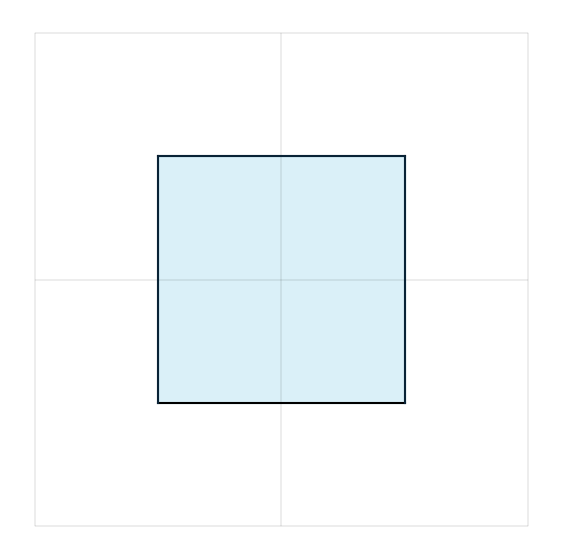

The diagram has been unknotted!
Processed: 1/1004 | reduced: 1 (100.00%)
Finished in 34.16 seconds.
Non-reduced results have been saved to 'not_reduced_results.txt'


In [4]:
import concurrent.futures
import time

cores=1


# 1. Define a helper function to process a single unknot
# This will run independently on your 16 different cores
def process_unknot(args):
    i, unknot = args
    #V=simplify_v1b_T_and_rotate(unknot)
    V=simplify_v1b_pushT_hingeT_and_rotate(unknot)
    #V=apply_full_simplification(unknot, max_iterations=1)
    #VS = All_Virtual_Boxes_Simplification_Updated_Not_Verbose(unknot)
    
    # Return a tuple indicating the category and the data to save
    if (len(V) // 2) > 2:
        return ('not_reduced', V)
    else:
        return ('reduced', i)

# 2. Main execution block (CRITICAL for multiprocessing in Python)
if __name__ == '__main__':
    reduced_knots=[]
    not_reduced_knots=[]
    
    total_unknots = len(unknots)
    start_time = time.time()

    print(f"Starting parallel processing on {cores} cores for {total_unknots} unknots...")
    
    # Open a text file in write mode ('w') to save the non-simple VS[-1] data
    with open('not_reduced_results.txt', 'w') as out_file:
        
        # 3. Spin up 16 parallel processes
        with concurrent.futures.ProcessPoolExecutor(max_workers=cores) as executor:
            
            # executor.map distributes the unknots to available cores
            #FOR DEMO PURPOSES ONLY WE ARE ONLY USING THE FIRST KNOT THE LINE BELOW DOES ALL OF THEM
            results = executor.map(process_unknot, enumerate(unknots[0:1]))
            #results = executor.map(process_unknot, enumerate(unknots))
            
            # 4. Collect results as they finish and print progress
            for processed_count, result in enumerate(results, 1):
                category, data = result
                
                if category == 'not_reduced':
                    not_reduced_knots.append(data)
                    # Write the data to the file, followed by a newline
                    out_file.write(f"{data}\n")
                    # Optional: force write to disk immediately (good for very long runs)
                    out_file.flush() 
                else:
                    reduced_knots.append(data)
                
                # Print progress periodically (e.g., every 5 items)
                if processed_count % 1 == 0 or processed_count == total_unknots:
                    percent_reduced = (len(reduced_knots) / processed_count) * 100
                    print(f"Processed: {processed_count}/{total_unknots} | "
                          f"reduced: {len(reduced_knots)} ({percent_reduced:.2f}%)")

    end_time = time.time()
    print(f"Finished in {end_time - start_time:.2f} seconds.")
    print("Non-reduced results have been saved to 'not_reduced_results.txt'")

In [5]:
""""v1b_simple_unknots = []
# Open the file and read it line by line
with open('not_v_1_b_simple_results.txt', 'r') as in_file:
    for line in in_file:
        line = line.strip() # Clean up any extra spaces or newlines
        
        if line: # Make sure it's not a blank line
            # Safely turn the string back into a Python list/tuple
            knot = ast.literal_eval(line)
            v1b_simple_unknots.append(knot)"""

'"v1b_simple_unknots = []\n# Open the file and read it line by line\nwith open(\'not_v_1_b_simple_results.txt\', \'r\') as in_file:\n    for line in in_file:\n        line = line.strip() # Clean up any extra spaces or newlines\n        \n        if line: # Make sure it\'s not a blank line\n            # Safely turn the string back into a Python list/tuple\n            knot = ast.literal_eval(line)\n            v1b_simple_unknots.append(knot)'

In [6]:
""""import concurrent.futures
import time

# 1. Define a helper function to process a single unknot
# This will run independently on your 16 different cores
def process_unknot(args):
    i, unknot = args
    V=perform_v1b_corner_rigid_simplifications(unknot)
    #VS = All_Virtual_Boxes_Simplification_Updated_Not_Verbose(unknot)
    
    # Return a tuple indicating the category and the data to save
    if (len(V) // 2) > 2:
        return ('not_v1b_gate_snowplow_simple', V)
    else:
        return ('v1b_gate_snowplow_simple', i)

# 2. Main execution block (CRITICAL for multiprocessing in Python)
if __name__ == '__main__':
    v_1b_rigid_gate_snowplow_simple = []
    not_v_1b_rigid_gate_snowplow_simple = []
    
    total_unknots = len(v1b_simple_unknots)
    start_time = time.time()

    print(f"Starting parallel processing on 16 cores for {total_unknots} unknots...")
    
    # Open a text file in write mode ('w') to save the non-simple VS[-1] data
    with open('not_v_1_b_or_gatesnowplow_simple_results.txt', 'w') as out_file:
        
        # 3. Spin up 16 parallel processes
        with concurrent.futures.ProcessPoolExecutor(max_workers=16) as executor:
            
            # executor.map distributes the unknots to available cores
            results = executor.map(process_unknot, enumerate(v1b_simple_unknots))
            
            # 4. Collect results as they finish and print progress
            for processed_count, result in enumerate(results, 1):
                category, data = result
                
                if category == 'not_v1b_gate_snowplow_simple':
                    not_v_1b_rigid_gate_snowplow_simple.append(data)
                    # Write the data to the file, followed by a newline
                    out_file.write(f"{data}\n")
                    # Optional: force write to disk immediately (good for very long runs)
                    out_file.flush() 
                else:
                    v_1b_rigid_gate_snowplow_simple.append(data)
                
                # Print progress periodically (e.g., every 5 items)
                if processed_count % 5 == 0 or processed_count == total_unknots:
                    percent_simple = (len(v_1b_rigid_gate_snowplow_simple) / processed_count) * 100
                    print(f"Processed: {processed_count}/{total_unknots} | "
                          f"v_1b_rigid_gate_snowplow_simple: {len(v_1b_rigid_gate_snowplow_simple)} ({percent_simple:.2f}%)")

    end_time = time.time()
    print(f"Finished in {end_time - start_time:.2f} seconds.")
    print("Non-simple results have been saved to 'not_v_1b_rigid_gate_snowplow_simple_results.txt'")"""

'"import concurrent.futures\nimport time\n\n# 1. Define a helper function to process a single unknot\n# This will run independently on your 16 different cores\ndef process_unknot(args):\n    i, unknot = args\n    V=perform_v1b_corner_rigid_simplifications(unknot)\n    #VS = All_Virtual_Boxes_Simplification_Updated_Not_Verbose(unknot)\n    \n    # Return a tuple indicating the category and the data to save\n    if (len(V) // 2) > 2:\n        return (\'not_v1b_gate_snowplow_simple\', V)\n    else:\n        return (\'v1b_gate_snowplow_simple\', i)\n\n# 2. Main execution block (CRITICAL for multiprocessing in Python)\nif __name__ == \'__main__\':\n    v_1b_rigid_gate_snowplow_simple = []\n    not_v_1b_rigid_gate_snowplow_simple = []\n    \n    total_unknots = len(v1b_simple_unknots)\n    start_time = time.time()\n\n    print(f"Starting parallel processing on 16 cores for {total_unknots} unknots...")\n    \n    # Open a text file in write mode (\'w\') to save the non-simple VS[-1] data\n   

In [7]:
v1b_snowplowgate_stuck_unknots = []
# Open the file and read it line by line
with open('not_v_1_b_or_gatesnowplow_simple_results.txt', 'r') as in_file:
    for line in in_file:
        line = line.strip() # Clean up any extra spaces or newlines
        
        if line: # Make sure it's not a blank line
            # Safely turn the string back into a Python list/tuple
            knot = ast.literal_eval(line)
            v1b_snowplowgate_stuck_unknots.append(knot)

FileNotFoundError: [Errno 2] No such file or directory: 'not_v_1_b_or_gatesnowplow_simple_results.txt'

In [ ]:
""""import concurrent.futures
import time

# 1. Define a helper function to process a single unknot
# This will run independently on your 16 different cores
def process_unknot(args):
    i, unknot = args
    V=apply_full_simplification(unknot, max_iterations=1)
    #V=perform_v1b_corner_rigid_simplifications(unknot)
    #VS = All_Virtual_Boxes_Simplification_Updated_Not_Verbose(unknot)
    
    # Return a tuple indicating the category and the data to save
    if (len(V) // 2) > 2:
        return ('not_pushT_simple', V)
    else:
        return ('pushT_simple', i)

# 2. Main execution block (CRITICAL for multiprocessing in Python)
if __name__ == '__main__':
    pushT_simple = []
    not_pushT_simple = []
    
    total_unknots = len(v1b_snowplowgate_stuck_unknots)
    start_time = time.time()

    print(f"Starting parallel processing on 16 cores for {total_unknots} unknots...")
    
    # Open a text file in write mode ('w') to save the non-simple VS[-1] data
    with open('not_pushT_simple.txt', 'w') as out_file:
        
        # 3. Spin up 16 parallel processes
        with concurrent.futures.ProcessPoolExecutor(max_workers=16) as executor:
            
            # executor.map distributes the unknots to available cores
            results = executor.map(process_unknot, enumerate(v1b_snowplowgate_stuck_unknots))
            
            # 4. Collect results as they finish and print progress
            for processed_count, result in enumerate(results, 1):
                category, data = result
                
                if category == 'not_pushT_simple':
                    not_pushT_simple.append(data)
                    # Write the data to the file, followed by a newline
                    out_file.write(f"{data}\n")
                    # Optional: force write to disk immediately (good for very long runs)
                    out_file.flush() 
                else:
                    pushT_simple.append(data)
                
                # Print progress periodically (e.g., every 5 items)
                if processed_count % 5 == 0 or processed_count == total_unknots:
                    percent_simple = (len(pushT_simple) / processed_count) * 100
                    print(f"Processed: {processed_count}/{total_unknots} | "
                          f"pushT_simple: {len(pushT_simple)} ({percent_simple:.2f}%)")

    end_time = time.time()
    print(f"Finished in {end_time - start_time:.2f} seconds.")
    print("Non-simple results have been saved to 'not_pushT_simple.txt'")"""